In [1]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)

# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'0': 404, '1': 620}


In [2]:
sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

Basis gates used: OrderedDict({'x': 1, 'measure': 1})


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

All imports OK ✅


In [4]:
p_true = 0.3

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

Problem defined ✅


In [10]:
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# Build noise model
noise_model_test = NoiseModel()
error_1q = depolarizing_error(0.75, 1)
noise_model_test.add_all_qubit_quantum_error(
    error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# ── Clean baseline ──
sampler_clean = AerSampler(
    run_options={"shots": 1024}         # shots in run_options
)
iae_clean = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_clean
)
result_clean = iae_clean.estimate(problem)
print(f"p=0.00 | Estimate: {result_clean.estimation:.4f} | Queries: {result_clean.num_oracle_queries}")

# ── Noisy run ──
sampler_noisy = AerSampler(
    backend_options={"noise_model": noise_model_test},  # ✅ noise in backend_options
    run_options={"shots": 1024}                         # ✅ shots in run_options
)
iae_noisy = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_noisy
)
result_noisy = iae_noisy.estimate(problem)
print(f"p=0.75 | Estimate: {result_noisy.estimation:.4f} | Queries: {result_noisy.num_oracle_queries}")

# ── Difference check ──
diff = abs(result_clean.estimation - result_noisy.estimation)
print(f"\nDifference: {diff:.4f}")
if diff < 0.01:
    print("❌ Noise is NOT being applied!")
else:
    print("✅ Noise IS affecting the estimate!")

p=0.00 | Estimate: 0.3009 | Queries: 4096
p=0.75 | Estimate: 0.5131 | Queries: 5120

Difference: 0.2123
✅ Noise IS affecting the estimate!


In [ ]:
import numpy as np
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ── Parameters ──
#epsilon_values = np.logspace(-3, -1, 15).tolist()
#noise_levels   = [0.0] + np.logspace(-3, np.log10(0.75), 15).tolist()

epsilon_values = np.linspace(0.001, 0.1, 15).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.75, 15).tolist()

N_REPEATS      = 10  # runs per (eps, noise) combination

def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        p_2q = min(p_depol * 10, 0.9375)
        error_1q = depolarizing_error(p_1q, 1)
        error_2q = depolarizing_error(p_2q, 2)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        noise_model.add_all_qubit_quantum_error(
            error_2q, ['cx', 'cz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": 1024}
        )
    else:
        sampler = AerSampler(run_options={"shots": 1024})
    return sampler

# ── Sweep ──
sweep_results = []
total_runs    = len(epsilon_values) * len(noise_levels) * N_REPEATS
run_count     = 0

for p_noise in noise_levels:
    print(f"\n--- Noise p = {p_noise:.5f} ---")
    sampler = build_noisy_sampler(p_noise)

    for eps in epsilon_values:
        run_count += 1

        estimates = []
        queries   = []

        for repeat in range(N_REPEATS):
            try:
                iae = IterativeAmplitudeEstimation(
                    epsilon_target=eps,
                    alpha=0.05,
                    sampler=sampler,
                )
                result = iae.estimate(problem)
                estimates.append(result.estimation)
                queries.append(result.num_oracle_queries)

            except Exception as e:
                estimates.append(0.0)
                queries.append(0)

        # ── Compute RMSE across 10 runs ──
        estimates  = np.array(estimates)
        rmse       = np.sqrt(np.mean((estimates - p_true) ** 2))
        avg_est    = np.mean(estimates)
        avg_queries = np.mean(queries)

        # ✅ Reject if RMSE > epsilon (noise overwhelmed accuracy)
        collapsed  = rmse > eps

        sweep_results.append({
            "epsilon"    : eps,
            "noise"      : p_noise,
            "queries"    : avg_queries,
            "avg_est"    : avg_est,
            "rmse"       : rmse,
            "collapsed"  : collapsed,
        })

        status = "💀 FAILED" if collapsed else "✅ OK"
        print(f"  [{run_count}/{total_runs}] eps={eps:.5f} | "
              f"Avg Queries={avg_queries:>7.1f} | "
              f"Avg Est={avg_est:.4f} | "
              f"RMSE={rmse:.5f} | {status}")

print(f"\n✅ Sweep complete — {total_runs} combinations x {N_REPEATS} repeats")


--- Noise p = 0.00000 ---


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2003535249.py:39: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [1/2400] eps=0.00100 | Avg Queries=120627.2 | Avg Est=0.3000 | RMSE=0.00007 | ✅ OK
  [2/2400] eps=0.00139 | Avg Queries=92774.4 | Avg Est=0.3001 | RMSE=0.00008 | ✅ OK
  [3/2400] eps=0.00193 | Avg Queries=87244.8 | Avg Est=0.3000 | RMSE=0.00007 | ✅ OK
  [4/2400] eps=0.00268 | Avg Queries=87756.8 | Avg Est=0.3000 | RMSE=0.00010 | ✅ OK
  [5/2400] eps=0.00373 | Avg Queries=39936.0 | Avg Est=0.3001 | RMSE=0.00057 | ✅ OK
  [6/2400] eps=0.00518 | Avg Queries=10854.4 | Avg Est=0.3004 | RMSE=0.00071 | ✅ OK
  [7/2400] eps=0.00720 | Avg Queries= 5734.4 | Avg Est=0.2998 | RMSE=0.00105 | ✅ OK
  [8/2400] eps=0.01000 | Avg Queries= 6246.4 | Avg Est=0.3003 | RMSE=0.00137 | ✅ OK
  [9/2400] eps=0.01389 | Avg Queries= 5939.2 | Avg Est=0.2996 | RMSE=0.00147 | ✅ OK
  [10/2400] eps=0.01931 | Avg Queries= 6553.6 | Avg Est=0.3004 | RMSE=0.00158 | ✅ OK
  [11/2400] eps=0.02683 | Avg Queries= 7168.0 | Avg Est=0.2997 | RMSE=0.00069 | ✅ OK
  [12/2400] eps=0.03728 | Avg Queries= 6860.8 | Avg Est=0.3006 | RMSE=0.0

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2003535249.py:39: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [16/2400] eps=0.00100 | Avg Queries=109670.4 | Avg Est=0.3000 | RMSE=0.00008 | ✅ OK
  [17/2400] eps=0.00139 | Avg Queries=95334.4 | Avg Est=0.3000 | RMSE=0.00013 | ✅ OK
  [18/2400] eps=0.00193 | Avg Queries=104448.0 | Avg Est=0.3000 | RMSE=0.00008 | ✅ OK
  [19/2400] eps=0.00268 | Avg Queries=102502.4 | Avg Est=0.3000 | RMSE=0.00007 | ✅ OK
  [20/2400] eps=0.00373 | Avg Queries=21196.8 | Avg Est=0.2999 | RMSE=0.00060 | ✅ OK
  [21/2400] eps=0.00518 | Avg Queries= 6041.6 | Avg Est=0.3004 | RMSE=0.00164 | ✅ OK
  [22/2400] eps=0.00720 | Avg Queries= 6963.2 | Avg Est=0.2996 | RMSE=0.00124 | ✅ OK
  [23/2400] eps=0.01000 | Avg Queries= 6451.2 | Avg Est=0.3006 | RMSE=0.00145 | ✅ OK
  [24/2400] eps=0.01389 | Avg Queries= 6348.8 | Avg Est=0.3003 | RMSE=0.00094 | ✅ OK
  [25/2400] eps=0.01931 | Avg Queries= 6246.4 | Avg Est=0.3005 | RMSE=0.00156 | ✅ OK
  [26/2400] eps=0.02683 | Avg Queries= 6041.6 | Avg Est=0.2996 | RMSE=0.00142 | ✅ OK
  [27/2400] eps=0.03728 | Avg Queries= 6041.6 | Avg Est=0.2997

...

  [196/2400] eps=0.00100 | Avg Queries=104857.6 | Avg Est=0.3459 | RMSE=0.04957 | 💀 FAILED
  [197/2400] eps=0.00139 | Avg Queries=103833.6 | Avg Est=0.3448 | RMSE=0.04974 | 💀 FAILED
  [198/2400] eps=0.00193 | Avg Queries=97587.2 | Avg Est=0.3299 | RMSE=0.03172 | 💀 FAILED
  [199/2400] eps=0.00268 | Avg Queries=95846.4 | Avg Est=0.3307 | RMSE=0.03741 | 💀 FAILED
  [200/2400] eps=0.00373 | Avg Queries=57651.2 | Avg Est=0.3368 | RMSE=0.04075 | 💀 FAILED
  [201/2400] eps=0.00518 | Avg Queries= 5632.0 | Avg Est=0.3440 | RMSE=0.05002 | 💀 FAILED
  [202/2400] eps=0.00720 | Avg Queries= 5427.2 | Avg Est=0.3375 | RMSE=0.04139 | 💀 FAILED
  [203/2400] eps=0.01000 | Avg Queries= 5836.8 | Avg Est=0.3489 | RMSE=0.05319 | 💀 FAILED
  [204/2400] eps=0.01389 | Avg Queries= 5222.4 | Avg Est=0.3295 | RMSE=0.03103 | 💀 FAILED
  [205/2400] eps=0.01931 | Avg Queries= 5632.0 | Avg Est=0.3418 | RMSE=0.04440 | 💀 FAILED
  [206/2400] eps=0.02683 | Avg Queries= 5222.4 | Avg Est=0.3290 | RMSE=0.03059 | 💀 FAILED
  [207/2

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2003535249.py:39: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [211/2400] eps=0.00100 | Avg Queries=114995.2 | Avg Est=0.3880 | RMSE=0.09166 | 💀 FAILED
  [212/2400] eps=0.00139 | Avg Queries=120627.2 | Avg Est=0.3760 | RMSE=0.07856 | 💀 FAILED
  [213/2400] eps=0.00193 | Avg Queries=116838.4 | Avg Est=0.3902 | RMSE=0.09319 | 💀 FAILED
  [214/2400] eps=0.00268 | Avg Queries=112947.2 | Avg Est=0.3840 | RMSE=0.08775 | 💀 FAILED
  [215/2400] eps=0.00373 | Avg Queries=18739.2 | Avg Est=0.4097 | RMSE=0.11627 | 💀 FAILED
  [216/2400] eps=0.00518 | Avg Queries=12083.2 | Avg Est=0.4118 | RMSE=0.11637 | 💀 FAILED
  [217/2400] eps=0.00720 | Avg Queries= 9728.0 | Avg Est=0.3923 | RMSE=0.09720 | 💀 FAILED
  [218/2400] eps=0.01000 | Avg Queries= 6246.4 | Avg Est=0.3883 | RMSE=0.09196 | 💀 FAILED
  [219/2400] eps=0.01389 | Avg Queries= 6553.6 | Avg Est=0.3758 | RMSE=0.07917 | 💀 FAILED
  [220/2400] eps=0.01931 | Avg Queries= 7372.8 | Avg Est=0.3967 | RMSE=0.10052 | 💀 FAILED
  [221/2400] eps=0.02683 | Avg Queries= 5734.4 | Avg Est=0.3934 | RMSE=0.10008 | 💀 FAILED
  [222

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2003535249.py:39: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [226/2400] eps=0.00100 | Avg Queries=42086.4 | Avg Est=0.4920 | RMSE=0.19241 | 💀 FAILED
  [227/2400] eps=0.00139 | Avg Queries=40345.6 | Avg Est=0.4979 | RMSE=0.19805 | 💀 FAILED
  [228/2400] eps=0.00193 | Avg Queries=37785.6 | Avg Est=0.4953 | RMSE=0.19553 | 💀 FAILED
  [229/2400] eps=0.00268 | Avg Queries=50483.2 | Avg Est=0.4980 | RMSE=0.19821 | 💀 FAILED
  [230/2400] eps=0.00373 | Avg Queries=46796.8 | Avg Est=0.5006 | RMSE=0.20079 | 💀 FAILED
  [231/2400] eps=0.00518 | Avg Queries=24064.0 | Avg Est=0.5028 | RMSE=0.20286 | 💀 FAILED
  [232/2400] eps=0.00720 | Avg Queries= 7065.6 | Avg Est=0.5001 | RMSE=0.20026 | 💀 FAILED
  [233/2400] eps=0.01000 | Avg Queries= 3891.2 | Avg Est=0.4897 | RMSE=0.19178 | 💀 FAILED
  [234/2400] eps=0.01389 | Avg Queries= 3891.2 | Avg Est=0.4980 | RMSE=0.19813 | 💀 FAILED
  [235/2400] eps=0.01931 | Avg Queries= 3891.2 | Avg Est=0.5020 | RMSE=0.20211 | 💀 FAILED
  [236/2400] eps=0.02683 | Avg Queries= 3379.2 | Avg Est=0.4979 | RMSE=0.19801 | 💀 FAILED
  [237/240

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2127872065.py:58: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\2127872065.py:58: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Percy Cheng\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


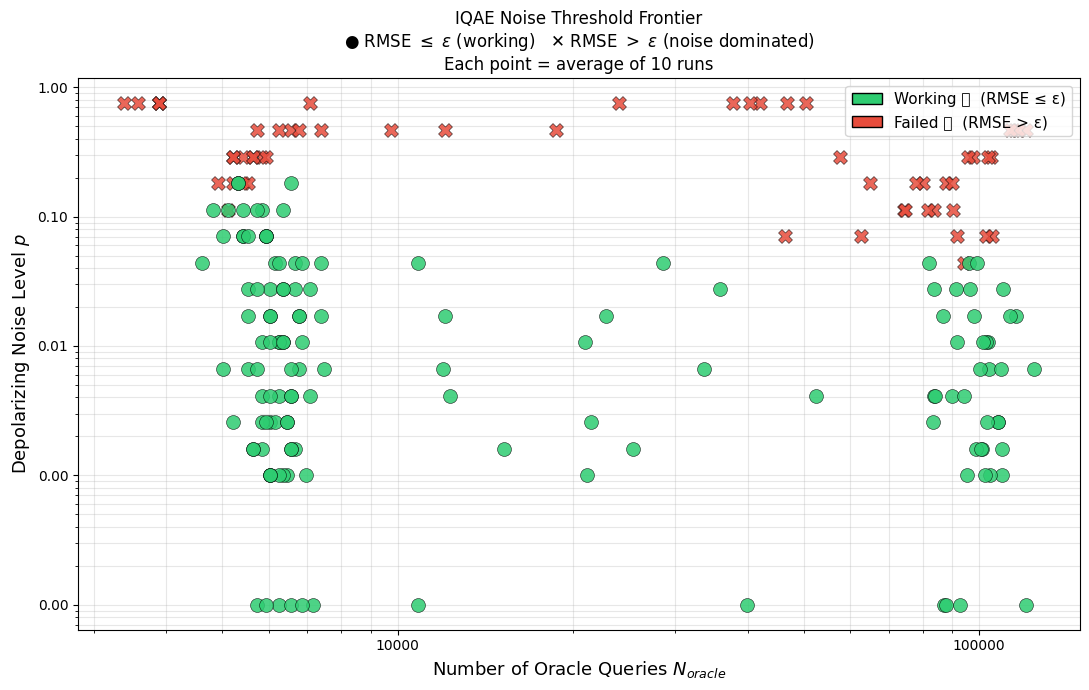

In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import numpy as np

fig, ax = plt.subplots(figsize=(11, 7))

for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'

    ax.scatter(
        entry["queries"],
        entry["noise"] if entry["noise"] > 0 else 1e-4,
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

# ── Log scale with ACTUAL numbers, not 10^x ──
ax.set_xscale('log')
ax.set_yscale('log')

# ✅ Force real numbers on both axes instead of 10^x notation
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

# ✅ Ensure tick marks show actual values
ax.xaxis.get_major_formatter().set_scientific(False)
ax.yaxis.get_major_formatter().set_scientific(False)

ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)

ax.grid(True, which='both', alpha=0.3)

legend_elements = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label=f'Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label=f'Failed 💀  (RMSE > ε)'),
]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\642831031.py:42: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_14392\642831031.py:42: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


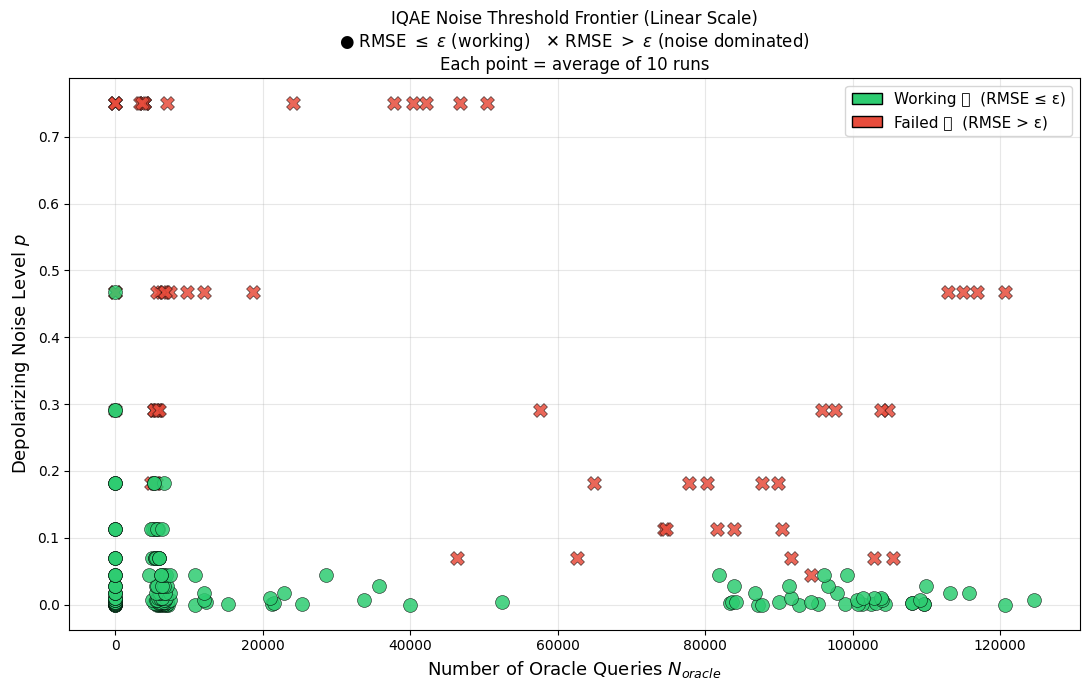

In [26]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 7))

for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'

    ax.scatter(
        entry["queries"],
        entry["noise"] if entry["noise"] > 0 else 0,
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier (Linear Scale)\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)

ax.grid(True, which='both', alpha=0.3)

legend_elements = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()